# A perceptron you can audit

_Mihai Dan Nadăș · first written January 2025 · revised August 2026_

This notebook implements the binary perceptron update directly, with two weights and one bias. The dataset is intentionally small and linearly separable so that every prediction and parameter update can be inspected. No claim is made that this toy task is representative of real classification work.

## The task

For an integer $x$, construct a point $(x_1, x_2)$ as follows:

$$x_2 = \begin{cases}x_1 & \text{if } x_1 \text{ is even} \\ 2x_1 & \text{if } x_1 \text{ is odd.}\end{cases}$$

Points on $x_2=x_1$ receive class 0; points on $x_2=2x_1$ receive class 1. A linear classifier predicts class 1 when

$$z(x_1,x_2)=w_1x_1+w_2x_2+b \ge 0.$$

When $w_2 \ne 0$, the decision boundary has slope $-w_1/w_2$ and intercept $-b/w_2$.

In [1]:
import random

import matplotlib.pyplot as plt
import pandas as pd


def make_dataset(items_per_class=10, seed=42):
    rng = random.Random(seed)
    even = rng.sample(range(2, 101, 2), items_per_class)
    odd = rng.sample(range(1, 100, 2), items_per_class)
    class_zero = [(x, x, 0) for x in even]
    class_one = [(x, 2 * x, 1) for x in odd]
    rng.shuffle(class_zero)
    rng.shuffle(class_one)
    train = class_zero[:8] + class_one[:8]
    test = class_zero[8:] + class_one[8:]
    rng.shuffle(train)
    rng.shuffle(test)
    return train, test


train, test = make_dataset()
assert len(train) == 16 and len(test) == 4
assert sum(label == 1 for *_, label in train) == 8
pd.DataFrame(train, columns=['x1', 'x2', 'class']).head()

,x1,x2,class
0,5,10,1
1,65,130,1
2,16,16,0
3,82,82,0
4,3,6,1


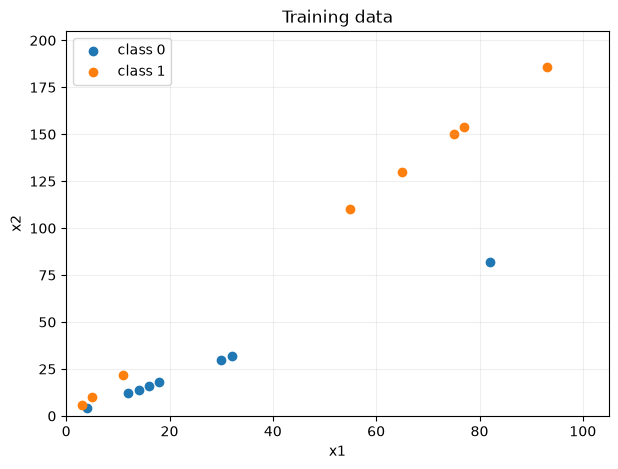

In [2]:
def score(x1, x2, w1, w2, bias):
    return w1 * x1 + w2 * x2 + bias


def predict(x1, x2, w1, w2, bias):
    return int(score(x1, x2, w1, w2, bias) >= 0)


def accuracy(data, w1, w2, bias):
    correct = sum(predict(x1, x2, w1, w2, bias) == label for x1, x2, label in data)
    return correct / len(data)


def plot_data(data, *, boundary=None, title='Dataset'):
    frame = pd.DataFrame(data, columns=['x1', 'x2', 'class'])
    fig, ax = plt.subplots(figsize=(7, 5))
    for label, group in frame.groupby('class'):
        ax.scatter(group.x1, group.x2, label=f'class {label}')
    if boundary is not None:
        w1, w2, bias = boundary
        x_values = [0, 100]
        y_values = [(-w1 * x - bias) / w2 for x in x_values]
        ax.plot(x_values, y_values, color='black', label='decision boundary')
    ax.set(xlabel='x1', ylabel='x2', title=title, xlim=(0, 105), ylim=(0, 205))
    ax.legend()
    ax.grid(alpha=0.2)
    return fig, ax


plot_data(train, title='Training data')
plt.show()

## Training

For each mistake, the perceptron applies $w \leftarrow w + \eta(y-\hat{y})x$ and $b \leftarrow b + \eta(y-\hat{y})$. The table stores one row per epoch: the number of mistakes and the resulting parameters. It does not pretend that the last sample in an epoch summarizes the whole epoch.

In [3]:
def train_perceptron(data, *, learning_rate=0.01, epochs=10):
    w1 = w2 = bias = 0.0
    history = []
    for epoch in range(1, epochs + 1):
        mistakes = 0
        for x1, x2, label in data:
            prediction = predict(x1, x2, w1, w2, bias)
            update = learning_rate * (label - prediction)
            mistakes += prediction != label
            w1 += update * x1
            w2 += update * x2
            bias += update
        history.append(
            {'epoch': epoch, 'mistakes': mistakes, 'w1': w1, 'w2': w2, 'bias': bias}
        )
    return (w1, w2, bias), pd.DataFrame(history)


parameters, history = train_perceptron(train)
train_accuracy = accuracy(train, *parameters)
test_accuracy = accuracy(test, *parameters)
assert train_accuracy == 1.0 and test_accuracy == 1.0
print(f'parameters: w1={parameters[0]:.3f}, w2={parameters[1]:.3f}, bias={parameters[2]:.3f}')
print(f'train accuracy: {train_accuracy:.0%}; held-out accuracy: {test_accuracy:.0%}')
history

parameters: w1=-0.440, w2=0.340, bias=-0.040
train accuracy: 100%; held-out accuracy: 100%


,epoch,mistakes,w1,w2,bias
0,1,8,-0.44,0.34,-0.04
1,2,0,-0.44,0.34,-0.04
2,3,0,-0.44,0.34,-0.04
3,4,0,-0.44,0.34,-0.04
4,5,0,-0.44,0.34,-0.04
5,6,0,-0.44,0.34,-0.04
6,7,0,-0.44,0.34,-0.04
7,8,0,-0.44,0.34,-0.04
8,9,0,-0.44,0.34,-0.04
9,10,0,-0.44,0.34,-0.04


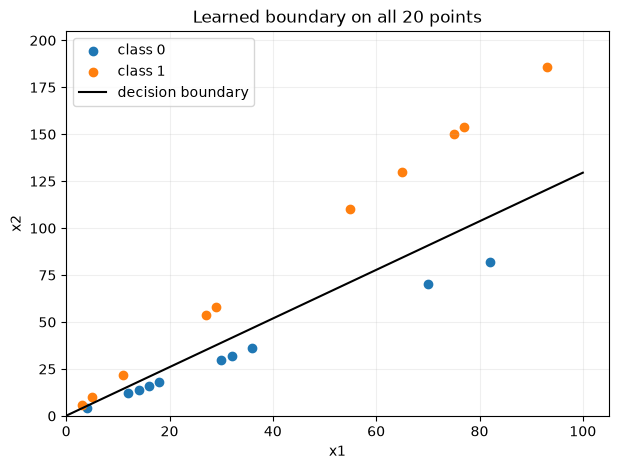

In [4]:
plot_data(train + test, boundary=parameters, title='Learned boundary on all 20 points')
plt.show()

## What this example establishes—and what it does not

The update rule finds a separator for this deterministic, linearly separable construction. The 100% held-out score covers only four points sampled from the same two lines; it is a consistency check, not evidence of generalization to a broader problem.

The perceptron convergence theorem guarantees a finite number of updates when a separating hyperplane exists, but it does not make the returned separator unique or optimal. For overlapping classes, the same algorithm will continue making mistakes instead of converging.

## Sources

- Frank Rosenblatt, [The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain](https://doi.org/10.1037/h0042519), *Psychological Review* 65(6), 1958.
- Albert B. J. Novikoff, [On Convergence Proofs on Perceptrons](https://doi.org/10.1145/321127.321128), *Proceedings of the Symposium on the Mathematical Theory of Automata*, 1962.